# 02 — DQN Training and Evaluation

This notebook trains a **vanilla DQN** agent on the project's custom autonomous-navigation environment.

## Algorithm components

1. Online Q-network and target Q-network.
2. Uniform Experience Replay.
3. Epsilon-greedy exploration with linear decay.
4. Bellman target with target-network bootstrapping.
5. Huber loss and gradient clipping.

The environment's potential-based shaping discount must match `DQNConfig.gamma`. The provided defaults already match. Start with the smoke test, then run a pilot (1,000–3,000 episodes) before a longer experiment.

In [1]:
from pathlib import Path
import sys


def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").exists() and (candidate / "src" / "navigation_rl").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the project root. Start Jupyter from the project folder."
    )


PROJECT_ROOT = find_project_root()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

# print("Project root:", PROJECT_ROOT)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from navigation_rl.environment import NavigationGridWorld
from navigation_rl.dqn import (
    DQNAgent,
    DQNConfig,
    TrainingConfig,
    train_agent,
    evaluate_policy,
    plot_training_history,
)

DEVICE = "cuda" if __import__("torch").cuda.is_available() else "cpu"
print("Device:", DEVICE)


Device: cpu


## 1. Smoke test

This short test verifies that interaction, replay insertion and gradient updates work before a long training run.

In [3]:
smoke_dqn_config = DQNConfig(
    replay_capacity=512,
    batch_size=16,
    learning_starts=16,
    train_frequency=1,
    target_update_interval=100,
    epsilon_decay_steps=1_000,
    hidden_dim=64,
    device=DEVICE,
)
smoke_agent = DQNAgent(smoke_dqn_config, seed=123)
smoke_env = NavigationGridWorld(gamma=smoke_dqn_config.gamma, max_steps=40)
obs, _ = smoke_env.reset(seed=123)

for step in range(120):
    action = smoke_agent.choose_action(obs, explore=True)
    next_obs, reward, terminated, truncated, info = smoke_env.step(action)
    smoke_agent.store_transition(obs, action, reward, next_obs, terminated)
    obs = next_obs
    if terminated or truncated:
        obs, _ = smoke_env.reset(seed=123 + step + 1)

assert len(smoke_agent.replay_buffer) == 120
assert smoke_agent.gradient_steps > 0
print("Smoke test passed")
print("Replay transitions:", len(smoke_agent.replay_buffer))
print("Gradient updates:", smoke_agent.gradient_steps)
print("Last loss:", smoke_agent.last_loss)


Smoke test passed
Replay transitions: 120
Gradient updates: 105
Last loss: 0.1743246614933014


## 2. Configure the experiment

For a first pilot, change `NUM_EPISODES` to 1,000–3,000. Once the curves and greedy evaluation are sensible, increase it (the repository default is 20,000 episodes). For research claims, repeat training with at least 3–5 independent seeds.

In [4]:
SEED = 42
NUM_EPISODES = 3_000    ###
NUM_EVAL_EPISODES = 200
MAX_STEPS = 180
VIDEO_EPISODES = [episode for episode in (1, 10, 100, 200, 500, 1_000) if episode <= NUM_EPISODES]

DQN_CONFIG = DQNConfig(
    learning_rate=1e-4,
    gamma=0.99,
    replay_capacity=100_000,
    batch_size=128,
    learning_starts=3_000,
    train_frequency=4,
    target_update_interval=2_000,
    epsilon_start=1.0,
    epsilon_end=0.05,
    epsilon_decay_steps=300_000,
    hidden_dim=256,
    max_grad_norm=10.0,
    device=DEVICE,
)

TRAIN_CONFIG = TrainingConfig(
    episodes=NUM_EPISODES,
    seed=SEED,
    evaluation_episodes=NUM_EVAL_EPISODES,
    evaluation_seed=50_000,
    max_steps=MAX_STEPS,
    log_interval=100,
    checkpoint_interval=0,  # Set e.g. 5_000 to save periodic checkpoints.
    output_dir=str(PROJECT_ROOT / "results"),
    show_progress=True,
)

agent = DQNAgent(DQN_CONFIG, seed=SEED)
env = NavigationGridWorld(gamma=DQN_CONFIG.gamma, max_steps=MAX_STEPS)
print("Observation dimension:", DQN_CONFIG.observation_dim)
print("Number of actions:", DQN_CONFIG.num_actions)


Observation dimension: 24
Number of actions: 4


## 3. Train DQN

This cell performs the actual training and writes `results/training_history.csv` and `results/dqn_final.pt`. It is intentionally not run automatically when the notebook is opened.

In [5]:
history = train_agent(agent, env, TRAIN_CONFIG, record_episodes=VIDEO_EPISODES)
display(history.tail())


DQN training:   0%|          | 0/3000 [00:00<?, ?episode/s]

,episode,episode_return,episode_length,success,blocked_actions,blocked_action_rate,epsilon,mean_loss,environment_steps,gradient_steps
2995,2996,30.160,35,True,1,0.028571,0.377326,0.065172,196634,48409
2996,2997,28.265,46,True,4,0.086957,0.377180,0.050648,196680,48421
2997,2998,29.595,28,True,2,0.071429,0.377091,0.041638,196708,48428
2998,2999,35.755,49,True,3,0.061224,0.376936,0.051840,196757,48440
2999,3000,37.275,58,True,1,0.017241,0.376753,0.051962,196815,48454


## 4. Learning curves

The success-rate curve is the primary learning diagnostic. Episode return alone is not enough because it includes step costs and potential-based shaping.

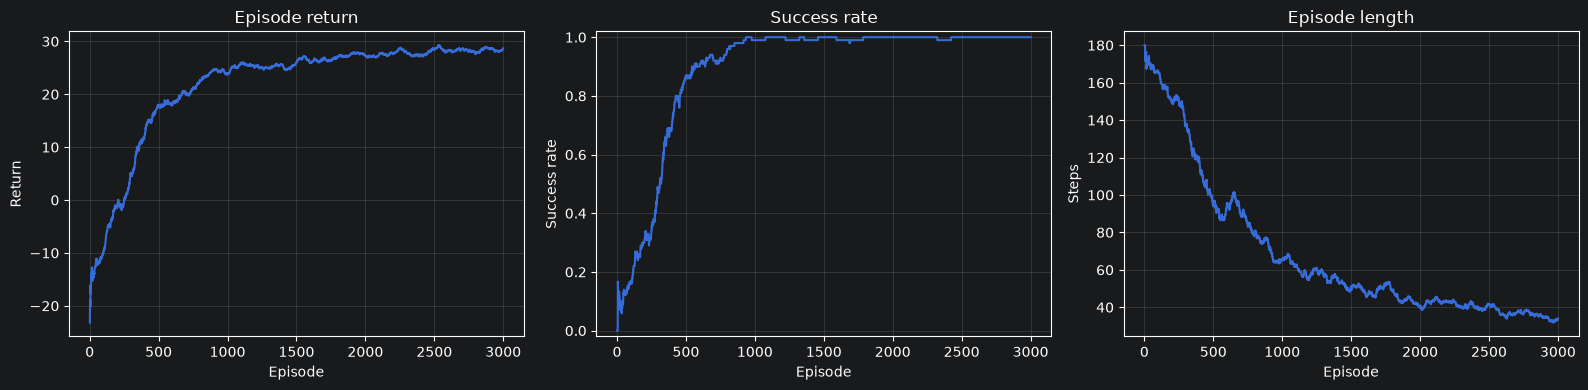

In [6]:
fig = plot_training_history(history, window=100)
plt.show()


## 5. Recorded Training Episode Videos

The videos below are generated from the exact environment states captured during the selected **training episodes**. They show the exploratory actions actually taken at that point in learning, not new rollouts from the final checkpoint. GIF is always generated; MP4 is also saved when FFmpeg is available.

Change `VIDEO_EPISODES` in the experiment configuration cell to select other episode numbers. If you change the selection, rerun the training cell so those episodes are recorded.

Episode 1 | success=False | steps=180
FFmpeg was not found; displaying the animated GIF instead.


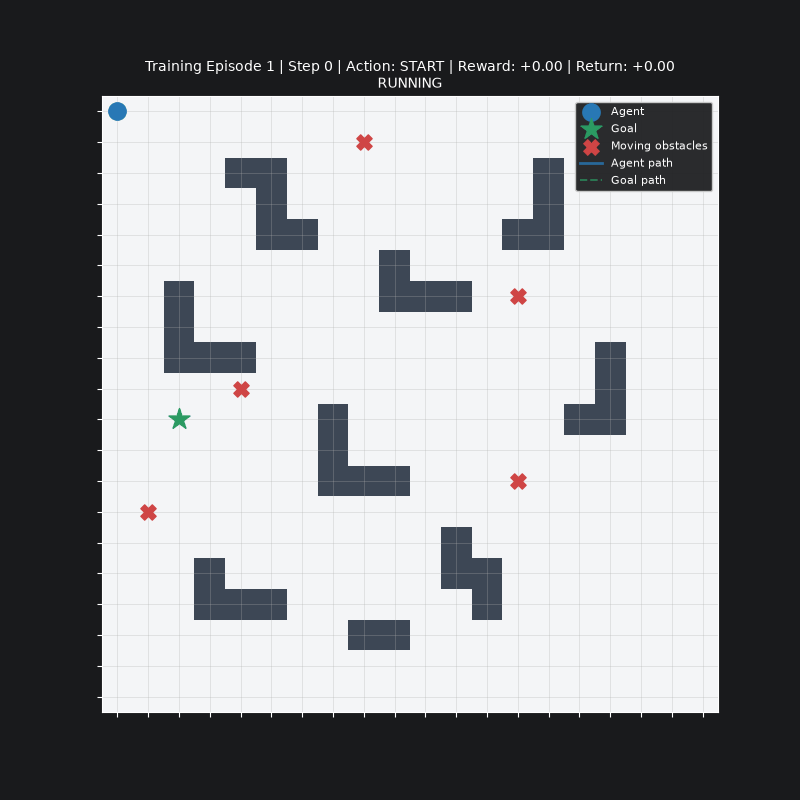

Episode 10 | success=False | steps=180
FFmpeg was not found; displaying the animated GIF instead.


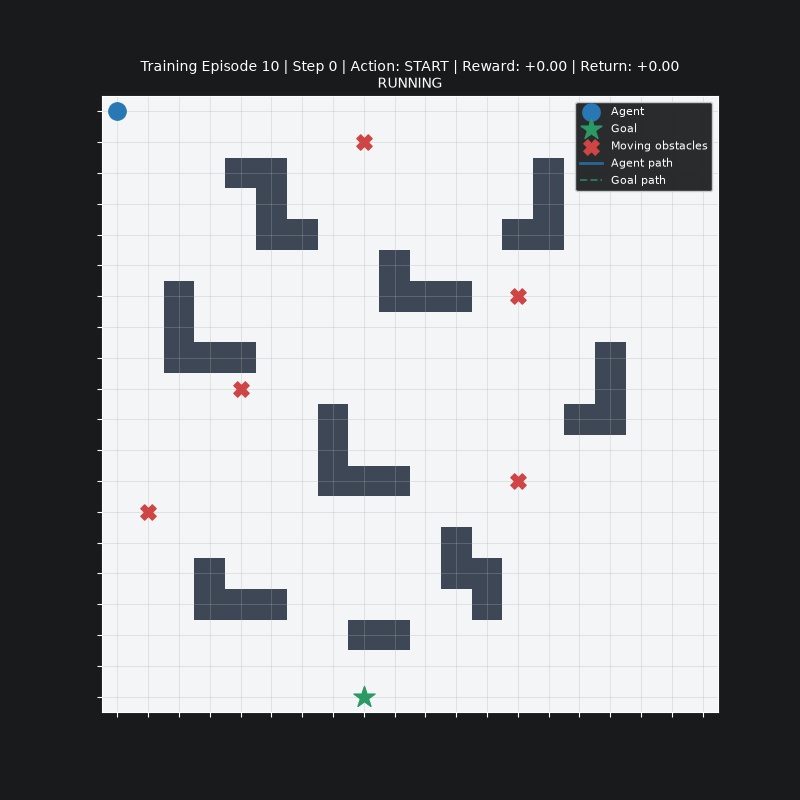

Episode 100 | success=True | steps=9
FFmpeg was not found; displaying the animated GIF instead.


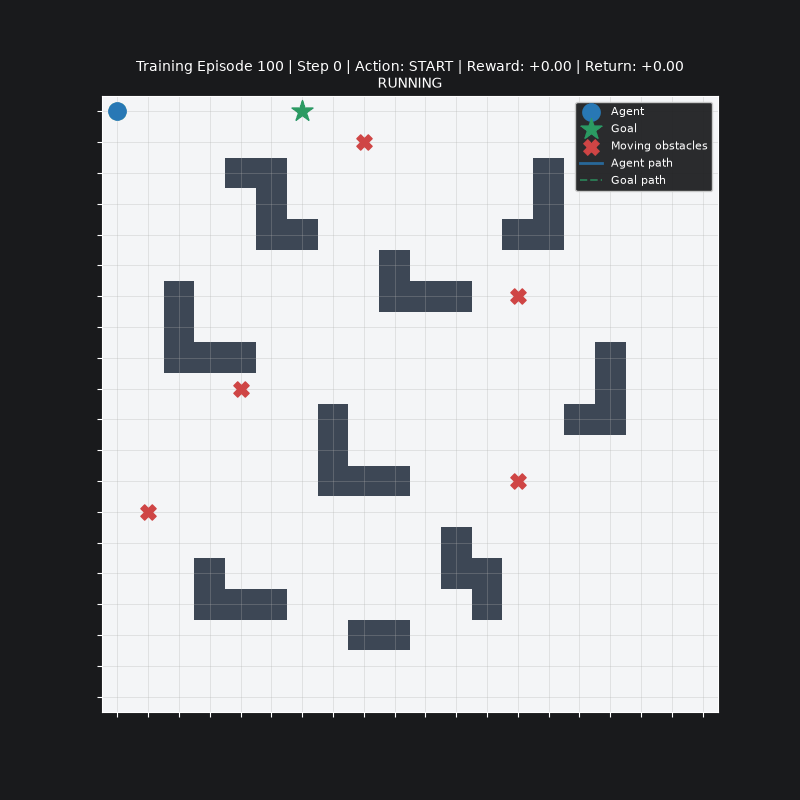

Episode 200 | success=True | steps=167
FFmpeg was not found; displaying the animated GIF instead.


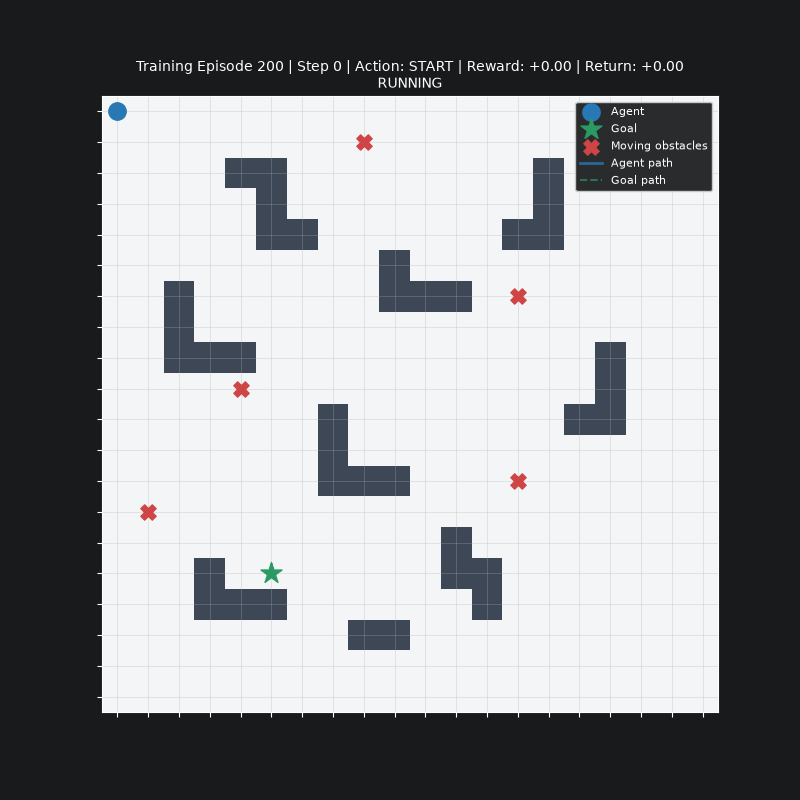

Episode 500 | success=True | steps=81
FFmpeg was not found; displaying the animated GIF instead.


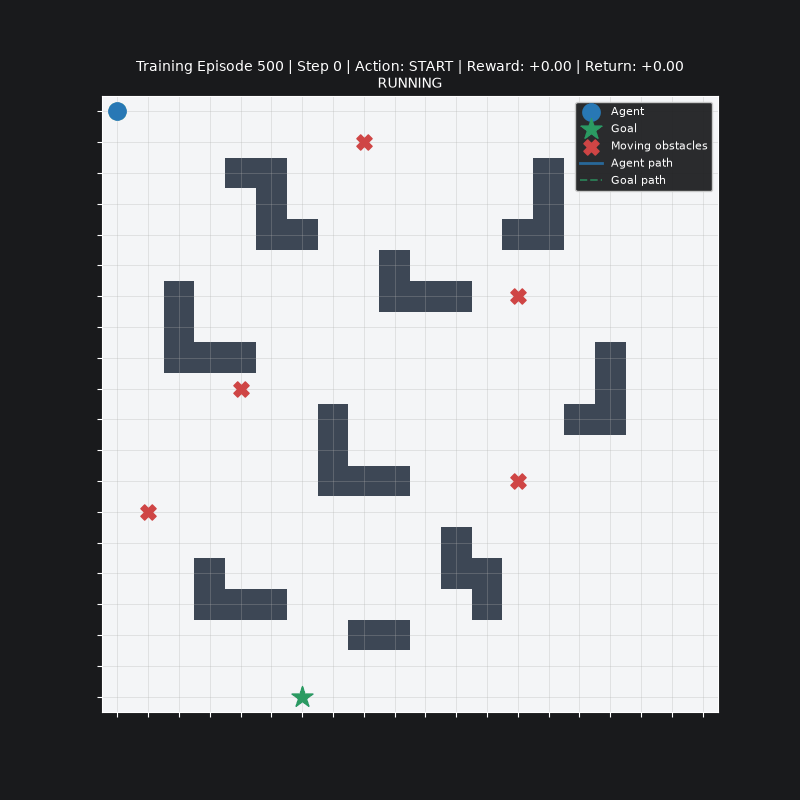

Episode 1000 | success=True | steps=76
FFmpeg was not found; displaying the animated GIF instead.


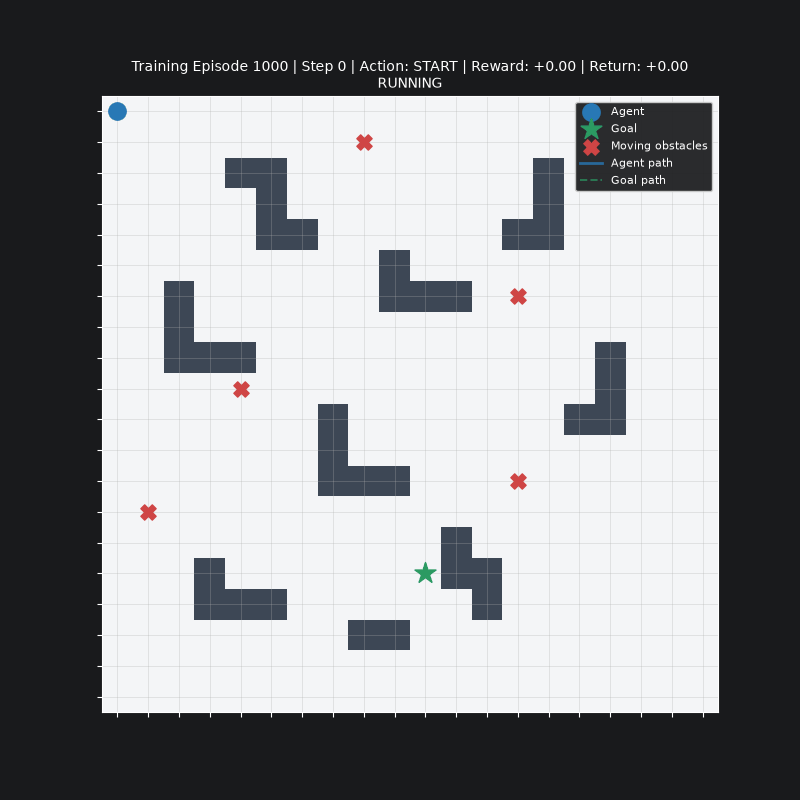

In [7]:
from IPython.display import Image, Video, display
from navigation_rl.episode_video import render_episode_videos

video_results = render_episode_videos(
    episode_dir=Path(TRAIN_CONFIG.output_dir) / "episodes",
    episodes=VIDEO_EPISODES,
    output_dir=Path(TRAIN_CONFIG.output_dir) / "videos",
    fps=10,
    save_mp4=True,
)

for video_result in video_results:
    print(
        f"Episode {video_result['episode']} | "
        f"success={video_result['success']} | steps={video_result['steps']}"
    )
    if video_result["mp4_path"]:
        display(Video(filename=video_result["mp4_path"], embed=True))
    else:
        print("FFmpeg was not found; displaying the animated GIF instead.")
        display(Image(filename=video_result["gif_path"]))


## 5. Greedy evaluation

Evaluation disables epsilon exploration and uses fresh seeds to sample new goal locations. The model is not updated during evaluation.

In [8]:
evaluation = evaluate_policy(
    agent,
    num_episodes=NUM_EVAL_EPISODES,
    seed=TRAIN_CONFIG.evaluation_seed,
    max_steps=MAX_STEPS,
)

evaluation_table = pd.DataFrame([evaluation], index=[f"DQN seed {SEED}"])
display(evaluation_table.round(4))


,success_rate,average_return,average_steps,blocked_action_rate
DQN seed 42,0.985,29.4198,21.85,0.0


## 6. Inspect one greedy trajectory

The full map shown here is for analysis. The agent still acts using only its observation vector.

{'goal': (16, 1), 'success': True, 'steps': 17, 'return': 28.380000000000003, 'blocked_actions': 0}


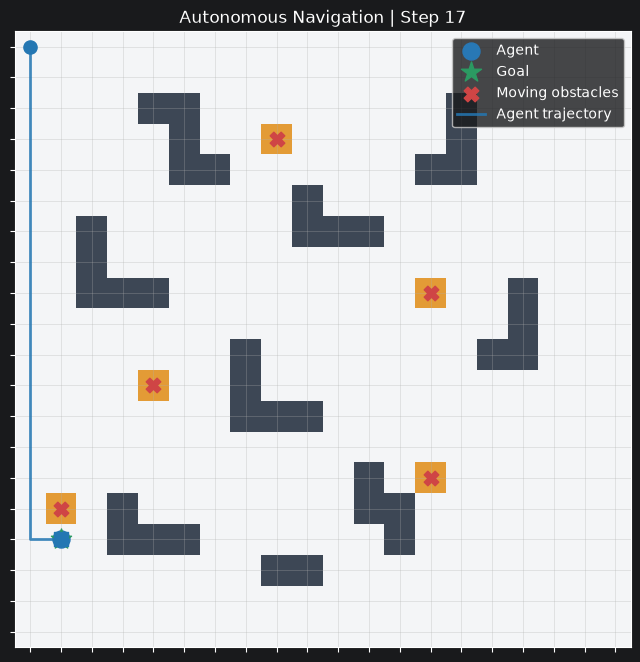

In [9]:
def record_greedy_episode(trained_agent, seed=60_001, max_steps=MAX_STEPS):
    rollout_env = NavigationGridWorld(gamma=trained_agent.config.gamma, max_steps=max_steps)
    observation, reset_info = rollout_env.reset(seed=seed)
    positions = [rollout_env.agent_pos]
    total_reward = 0.0
    blocked = 0
    terminated = truncated = False
    last_info = {}
    while not (terminated or truncated):
        action = trained_agent.choose_action(observation, explore=False)
        observation, reward, terminated, truncated, last_info = rollout_env.step(action)
        positions.append(rollout_env.agent_pos)
        total_reward += float(reward)
        blocked += int(last_info["blocked"])
    return rollout_env, positions, {
        "goal": reset_info["goal_position"],
        "success": bool(last_info.get("success", False)),
        "steps": int(last_info.get("steps", 0)),
        "return": total_reward,
        "blocked_actions": blocked,
    }


rollout_env, trajectory, trajectory_info = record_greedy_episode(agent)
print(trajectory_info)
fig, ax = plt.subplots(figsize=(8, 8))
rollout_env.render(ax=ax)
rows = [p[0] for p in trajectory]
cols = [p[1] for p in trajectory]
ax.plot(cols, rows, color="#2477b3", linewidth=2, alpha=0.85, label="Agent trajectory", zorder=6)
ax.scatter(cols[0], rows[0], color="#2477b3", s=90, marker="o", zorder=7)
ax.scatter(cols[-1], rows[-1], color="#2477b3", s=110, marker="s", zorder=7)
ax.legend(loc="upper right")
plt.show()


## 7. Save a reproducible run summary

Keep the training history and checkpoint with the experiment seed and configuration. Do not commit large checkpoints to Git unless there is a specific reason; `.gitignore` excludes them by default.

In [10]:
agent.save(
    PROJECT_ROOT / "results" / f"dqn_seed_{SEED}.pt",
    extra={"episodes": NUM_EPISODES, "evaluation": evaluation},
)
summary = {
    "seed": SEED,
    "episodes": NUM_EPISODES,
    **evaluation,
}
summary_path = PROJECT_ROOT / "results" / f"evaluation_seed_{SEED}.csv"
pd.DataFrame([summary]).to_csv(summary_path, index=False)
print("Saved:", summary_path)


Saved: C:\Users\mhmd\Desktop\ML\1403\Notebooks\RL\03_01\results\evaluation_seed_42.csv


## Interpretation notes

- A high training return does not guarantee high success rate; check greedy evaluation.
- Compare at least 3–5 seeds and report mean ± standard deviation.
- This baseline evaluates new goal positions on the same fixed wall layout. It does not yet claim transfer to unseen maps.
- If vanilla DQN plateaus, inspect blocked-action rate and the exploration schedule before increasing network size. The next controlled algorithmic comparison should be Double DQN; a recurrent model (DRQN) is a later extension for using observation history.

Observation dimension: 24
Number of actions: 4


DQN training:   0%|          | 0/1000 [00:00<?, ?episode/s]

,episode,episode_return,episode_length,success,blocked_actions,blocked_action_rate,epsilon,mean_loss,environment_steps,gradient_steps
995,996,19.41,23,True,6,0.260870,0.662310,0.057531,106639,25910
996,997,28.71,39,True,1,0.025641,0.662186,0.064385,106678,25920
997,998,22.70,100,True,11,0.110000,0.661870,0.093858,106778,25945
998,999,24.55,51,True,7,0.137255,0.661708,0.115146,106829,25958
999,1000,28.18,76,True,7,0.092105,0.661468,0.114402,106905,25977


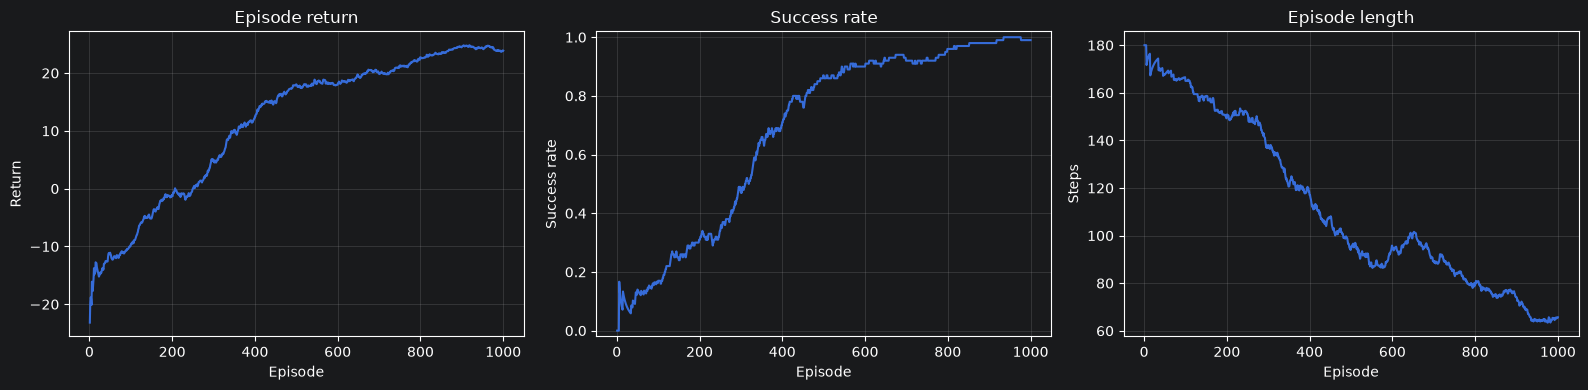

In [11]:
SEED = 42
NUM_EPISODES = 1_000    ###
NUM_EVAL_EPISODES = 200
MAX_STEPS = 180

DQN_CONFIG = DQNConfig(
    learning_rate=1e-4,
    gamma=0.99,
    replay_capacity=100_000,
    batch_size=128,
    learning_starts=3_000,
    train_frequency=4,
    target_update_interval=2_000,
    epsilon_start=1.0,
    epsilon_end=0.05,
    epsilon_decay_steps=300_000,
    hidden_dim=256,
    max_grad_norm=10.0,
    device=DEVICE,
)

TRAIN_CONFIG = TrainingConfig(
    episodes=NUM_EPISODES,
    seed=SEED,
    evaluation_episodes=NUM_EVAL_EPISODES,
    evaluation_seed=50_000,
    max_steps=MAX_STEPS,
    log_interval=100,
    checkpoint_interval=0,  # Set e.g. 5_000 to save periodic checkpoints.
    output_dir=str(PROJECT_ROOT / "results"),
    show_progress=True,
)

agent = DQNAgent(DQN_CONFIG, seed=SEED)
env = NavigationGridWorld(gamma=DQN_CONFIG.gamma, max_steps=MAX_STEPS)
print("Observation dimension:", DQN_CONFIG.observation_dim)
print("Number of actions:", DQN_CONFIG.num_actions)

history = train_agent(agent, env, TRAIN_CONFIG, record_episodes=VIDEO_EPISODES)
display(history.tail())

fig = plot_training_history(history, window=100)
plt.show()
